In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
from shapely.ops import unary_union
from shapely import wkt

def calculate_frontage_directions(parcels_path, roads_path):
    """
    Calculate frontage counts with directional information relative to parcel centroid

    Args:
        parcels_path: Path to parcels CSV file
        roads_path: Path to roads CSV file

    Returns:
        DataFrame with columns:
        ['Parcel UID', 'Open Frontage Count', 'Close Frontage Count',
         'Open Frontage Sides', 'Close Frontage Sides']
    """
    # Load and prepare data
    parcels_df = pd.read_csv(parcels_path)
    roads_df = pd.read_csv(roads_path)

    parcels = gpd.GeoDataFrame(parcels_df, geometry=gpd.GeoSeries.from_wkt(parcels_df['geom']))
    roads = gpd.GeoDataFrame(roads_df, geometry=gpd.GeoSeries.from_wkt(roads_df['WKT']))

    # Set CRS and filter valid geometries
    parcels.crs = roads.crs = "EPSG:4326"
    parcels = parcels[parcels.geometry.is_valid & ~parcels.geometry.is_empty]
    roads = roads[roads.geometry.is_valid & ~roads.geometry.is_empty]

    # Create unified geometries
    road_network = unary_union(roads.geometry)
    all_parcels = unary_union(parcels.geometry)
    buffer_distance = 0.0001  # ~10 meters in degrees
    free_space = all_parcels.buffer(buffer_distance).difference(all_parcels.buffer(-buffer_distance))

    results = []

    for idx, parcel in parcels.iterrows():
        parcel_poly = parcel.geometry
        centroid = parcel_poly.centroid
        boundary = parcel_poly.boundary

        # Calculate frontage segments
        road_frontage = boundary.intersection(road_network)
        free_space_frontage = boundary.intersection(free_space).difference(road_network)
        open_frontage = unary_union([road_frontage, free_space_frontage])
        close_frontage = boundary.difference(open_frontage)

        # Analyze segments relative to centroid
        def get_relative_directions(geom, center):
            if geom.is_empty:
                return 0, []

            segments = geom.geoms if geom.geom_type == 'MultiLineString' else [geom]
            directions = []

            for segment in segments:
                # Get midpoint of segment
                mid_point = segment.interpolate(0.5, normalized=True)

                # Calculate vector from centroid to midpoint
                dx = mid_point.x - center.x
                dy = mid_point.y - center.y

                # Determine compass direction
                angle = np.degrees(np.arctan2(dy, dx)) % 360
                if angle < 22.5 or angle >= 337.5:
                    direction = "E"
                elif angle < 67.5:
                    direction = "NE"
                elif angle < 112.5:
                    direction = "N"
                elif angle < 157.5:
                    direction = "NW"
                elif angle < 202.5:
                    direction = "W"
                elif angle < 247.5:
                    direction = "SW"
                elif angle < 292.5:
                    direction = "S"
                else:
                    direction = "SE"

                directions.append(direction)

            return len(segments), directions

        open_count, open_directions = get_relative_directions(open_frontage, centroid)
        close_count, close_directions = get_relative_directions(close_frontage, centroid)

        # Count unique directions
        def count_directions(directions):
            counts = {'N':0, 'NE':0, 'E':0, 'SE':0, 'S':0, 'SW':0, 'W':0, 'NW':0}
            for d in directions:
                counts[d] += 1
            return counts

        open_side_counts = count_directions(open_directions)
        close_side_counts = count_directions(close_directions)

        results.append({
            'Parcel UID': parcel['parcel_uid'],
            'Open Frontage Count': open_count,
            'Close Frontage Count': close_count,
            'Open Frontage Sides': ', '.join(f"{k}:{v}" for k,v in open_side_counts.items() if v > 0),
            'Close Frontage Sides': ', '.join(f"{k}:{v}" for k,v in close_side_counts.items() if v > 0)
        })

    return pd.DataFrame(results)

# Example usage
frontage_data = calculate_frontage_directions(
    '/content/parcels_abu_ftaira 1.csv',
    '/content/abu_fatira road 2.csv'
)

# Save and display results
frontage_data.to_csv('frontage_directions.csv', index=False)
print(frontage_data.head())

   Parcel UID  Open Frontage Count  Close Frontage Count Open Frontage Sides  \
0  TSTPA00391                    3                     2       N:1, S:1, W:1   
1  TSTPA00342                    2                     1            E:1, W:1   
2  TSTPA00389                    1                     2                 E:1   
3  TSTPA00338                    1                     0                SW:1   
4  TSTPA00273                    3                     2     NE:1, S:1, NW:1   

  Close Frontage Sides  
0             E:1, W:1  
1                  S:1  
2            N:1, SW:1  
3                       
4             E:1, W:1  


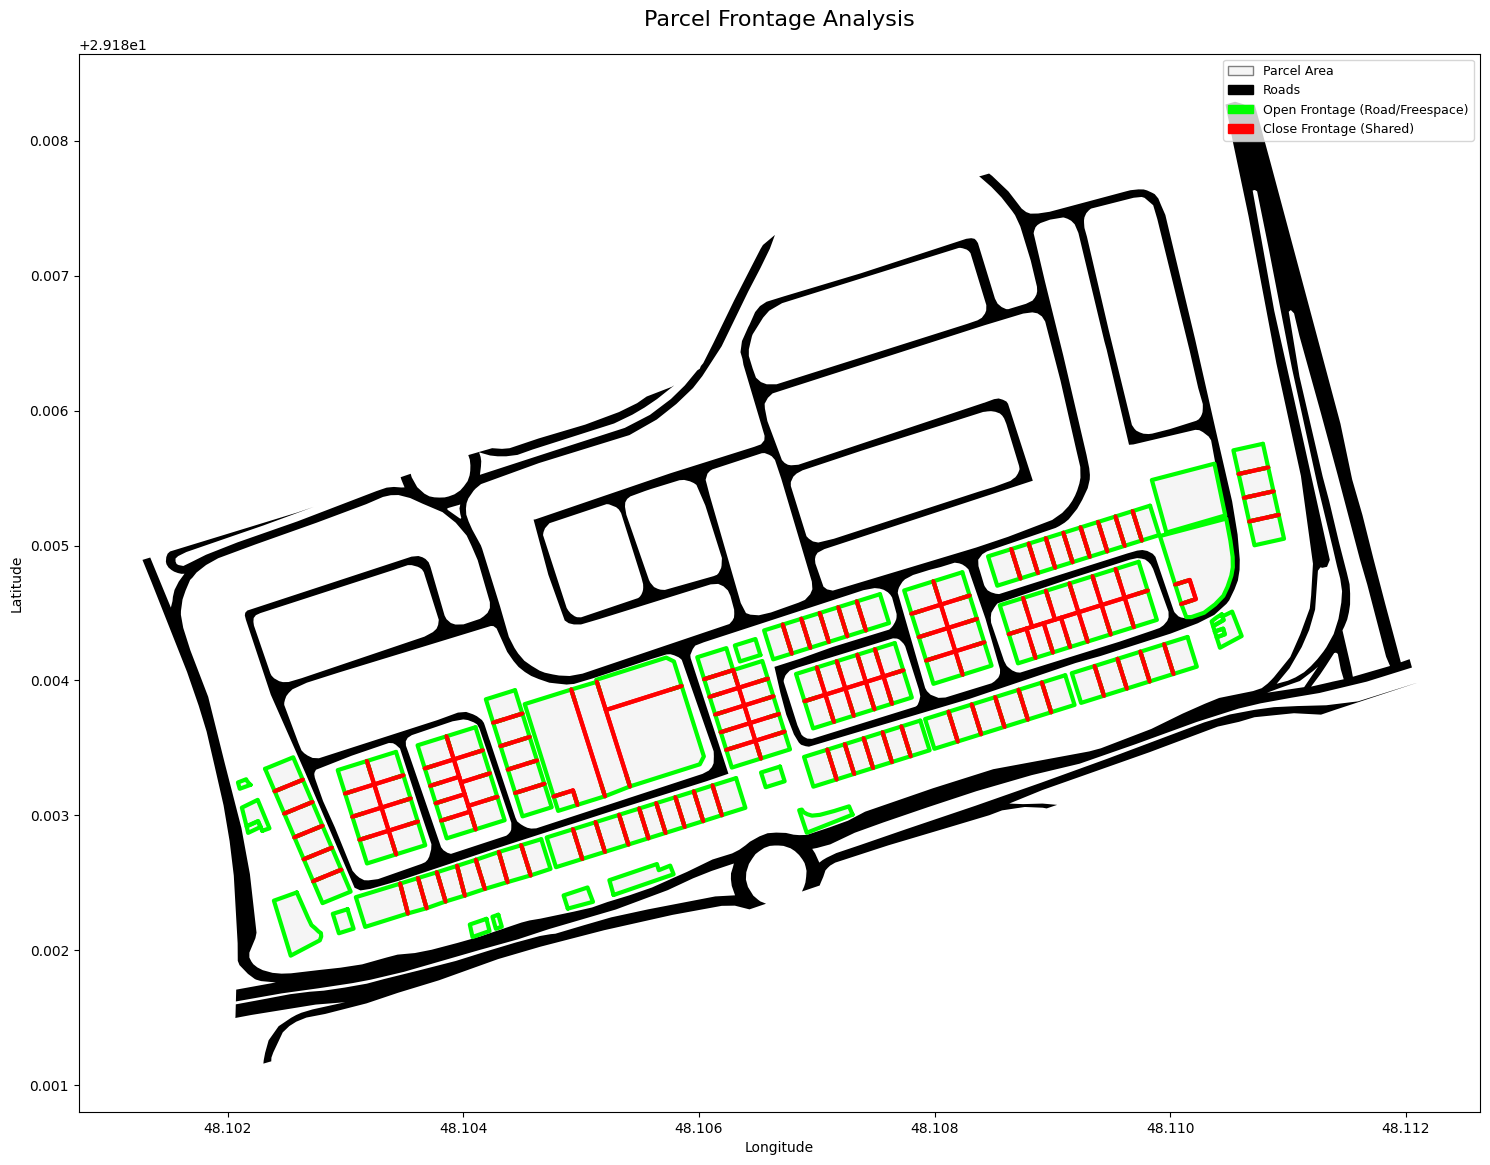

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from shapely.ops import unary_union
from shapely import wkt
from matplotlib.patches import Patch

# Load data as regular DataFrames first
parcels_df = pd.read_csv('/content/parcels_abu_ftaira 1.csv')
roads_df = pd.read_csv('/content/abu_fatira road 2.csv')

# Convert to GeoDataFrames with proper geometry
parcels = gpd.GeoDataFrame(parcels_df, geometry=gpd.GeoSeries.from_wkt(parcels_df['geom']))
roads = gpd.GeoDataFrame(roads_df, geometry=gpd.GeoSeries.from_wkt(roads_df['WKT']))

# Set CRS and filter valid geometries
parcels.crs = roads.crs = "EPSG:4326"
parcels = parcels[parcels.geometry.is_valid & ~parcels.geometry.is_empty]
roads = roads[roads.geometry.is_valid & ~roads.geometry.is_empty]

# Create unified geometries
road_network = unary_union(roads.geometry)
all_parcels = unary_union(parcels.geometry)
buffer_distance = 0.0001
free_space = all_parcels.buffer(buffer_distance).difference(all_parcels.buffer(-buffer_distance))

# Create figure
fig, ax = plt.subplots(figsize=(15, 12))

# Plot base layers
parcels.plot(ax=ax, color='whitesmoke', edgecolor='gray', linewidth=0.5)
roads.plot(ax=ax, color='black', linewidth=1.5)

# Color scheme
OPEN_COLOR = 'lime'
CLOSE_COLOR = 'red'

# Analyze and plot each parcel
for idx, parcel in parcels.iterrows():
    geom = parcel.geometry
    boundary = geom.boundary

    # Calculate frontages
    road_frontage = boundary.intersection(road_network)
    free_space_frontage = boundary.intersection(free_space).difference(road_network)
    open_frontage = unary_union([road_frontage, free_space_frontage])
    close_frontage = boundary.difference(open_frontage)

    # Plot frontages
    def plot_frontage(geom, color):
        if geom.is_empty:
            return

        segments = geom.geoms if geom.geom_type == 'MultiLineString' else [geom]

        for segment in segments:
            if segment.geom_type != 'LineString':
                continue

            # Plot the frontage line only
            x, y = segment.xy
            ax.plot(x, y, color=color, linewidth=3, solid_capstyle='round')

    # Plot open and closed frontages
    plot_frontage(open_frontage, OPEN_COLOR)
    plot_frontage(close_frontage, CLOSE_COLOR)

# Create legend (without directional elements)
legend_elements = [
    Patch(facecolor='whitesmoke', edgecolor='gray', label='Parcel Area'),
    Patch(color='black', label='Roads'),
    Patch(color=OPEN_COLOR, label='Open Frontage (Road/Freespace)'),
    Patch(color=CLOSE_COLOR, label='Close Frontage (Shared)')
]

ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

# Add title
ax.set_title('Parcel Frontage Analysis', fontsize=16, pad=20)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.tight_layout()
plt.show()